# Task 01: Python Programming, Data Analysis & Visualization
**Devixo Solutions AI/ML Internship Program**

**Dataset:** Air Quality Data in India (2015-2020), file `city_day.csv` (Kaggle, author: rohanrao)
**Domain:** Environment / air pollution (SDG 11, SDG 3, SDG 13)

**Questions I want to answer:** Which Indian cities are the most polluted? How does air quality change across seasons and years? Which pollutants are most closely linked to the AQI?

# Part 1: Data Loading and Data Understanding

## 1.1 Import libraries and 1.2 Load the dataset

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# works in Colab (file in same folder) and in the GitHub project (dataset/ folder)
DATA = next(p for p in ["city_day.csv", "../dataset/city_day.csv", "dataset/city_day.csv"] if os.path.exists(p))
IMG = "../images" if os.path.isdir("../images") else "images"
os.makedirs(IMG, exist_ok=True)

df = pd.read_csv(DATA)
print("Dataset loaded successfully")
print(df.shape)

Dataset loaded successfully
(29531, 16)


## 1.3 Display records (first 5, last 5, random sample)

In [2]:
print("First 5 records")
display(df.head())
print("Last 5 records")
display(df.tail())
print("Random sample")
display(df.sample(5, random_state=42))

First 5 records


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


Last 5 records


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
29526,Visakhapatnam,2020-06-27,15.02,50.94,7.68,25.06,19.54,12.47,0.47,8.55,23.30,2.24,12.07,0.73,41.0,Good
29527,Visakhapatnam,2020-06-28,24.38,74.09,3.42,26.06,16.53,11.99,0.52,12.72,30.14,0.74,2.21,0.38,70.0,Satisfactory
29528,Visakhapatnam,2020-06-29,22.91,65.73,3.45,29.53,18.33,10.71,0.48,8.42,30.96,0.01,0.01,0.00,68.0,Satisfactory
29529,Visakhapatnam,2020-06-30,16.64,49.97,4.05,29.26,18.80,10.03,0.52,9.84,28.30,0.00,0.00,0.00,54.0,Satisfactory
29530,Visakhapatnam,2020-07-01,15.00,66.00,0.40,26.85,14.05,5.20,0.59,2.10,17.05,NaN,NaN,NaN,50.0,Good


Random sample


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
22593,Mumbai,2017-01-08,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
22459,Mumbai,2016-08-27,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
24213,Patna,2016-05-15,58.50,NaN,11.23,17.05,28.29,NaN,1.14,5.13,24.20,0.14,0.64,0.31,137.0,Moderate
25301,Patna,2019-05-08,78.57,NaN,6.85,5.45,5.57,NaN,1.33,39.86,71.68,1.88,16.32,6.97,190.0,Moderate
20886,Lucknow,2017-11-06,200.80,NaN,40.04,50.59,60.42,35.47,1.22,9.71,42.18,0.15,1.19,NaN,339.0,Very Poor


## 1.4 and 1.5 Dataset information and shape
The dataset has daily air-quality readings for 26 Indian cities. Each row is one city on one day. `Date` is stored as text and has to be converted later.

In [3]:
df.info()
print()
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Column names:", list(df.columns))

<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  str    
 1   Date        29531 non-null  str    
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  str    
dtypes: float64(13), str(3)
memory usage: 3.6 MB

Rows: 29531
Columns: 16
Column names: ['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O

## 1.6 Column types
Knowing which columns are numerical and which are categorical decides which statistics and charts are valid. Means and correlations need numerical columns; counts, pie charts and count plots need categorical columns.

In [4]:
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()
print("Numerical:", numerical_cols)
print("Categorical/Text:", categorical_cols)
print("Date/Time column: Date (stored as text, will be converted)")

Numerical: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'AQI']
Categorical/Text: ['City', 'Date', 'AQI_Bucket']
Date/Time column: Date (stored as text, will be converted)


# Part 2: Data Cleaning and Preprocessing

## 2.1 Missing values

In [5]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
display(pd.DataFrame({"Missing": missing, "Percent": missing_pct}).sort_values("Percent", ascending=False))

,Missing,Percent
Xylene,18109,61.32
PM10,11140,37.72
NH3,10328,34.97
Toluene,8041,27.23
Benzene,5623,19.04
AQI,4681,15.85
AQI_Bucket,4681,15.85
PM2.5,4598,15.57
NOx,4185,14.17
O3,4022,13.62


**Observation:** Xylene is missing in about 61% of rows, PM10 in 38%, NH3 in 35%. AQI and AQI_Bucket are each missing in about 16% of rows.

## 2.3 Duplicate records and 2.4 Data types

In [6]:
print("Duplicates:", df.duplicated().sum())
df["Date"] = pd.to_datetime(df["Date"])
print(df.dtypes)

Duplicates: 0
City                     str
Date          datetime64[us]
PM2.5                float64
PM10                 float64
NO                   float64
NO2                  float64
NOx                  float64
NH3                  float64
CO                   float64
SO2                  float64
O3                   float64
Benzene              float64
Toluene              float64
Xylene               float64
AQI                  float64
AQI_Bucket               str
dtype: object


There are no duplicate records. `Date` was stored as text (object), so I converted it to datetime. This is needed for monthly and yearly analysis.

## 2.6 Invalid values

In [7]:
num_cols = ["PM2.5","PM10","NO","NO2","NOx","NH3","CO","SO2","O3","Benzene","Toluene","Xylene","AQI"]
print("Negative values per column:")
print((df[num_cols] < 0).sum())
print("Max AQI:", df["AQI"].max())
print("Date range:", df["Date"].min(), "to", df["Date"].max())

Negative values per column:
PM2.5      0
PM10       0
NO         0
NO2        0
NOx        0
NH3        0
CO         0
SO2        0
O3         0
Benzene    0
Toluene    0
Xylene     0
AQI        0
dtype: int64
Max AQI: 2049.0
Date range: 2015-01-01 00:00:00 to 2020-07-01 00:00:00


No pollutant has negative values. However, the maximum AQI is 2049, but the official AQI scale only goes from 0 to 500. Values above 500 are therefore invalid. I handle them below.

## 2.2 Handle missing values
My decisions and the reasons:
- **Xylene: column dropped.** About 61% of its values are missing. Filling that many values would mean inventing most of the column.
- **Rows with missing AQI: dropped.** AQI is my main variable, so I do not want to guess it.
- **Other pollutants: filled with the median of the same city.** Pollution levels differ a lot from city to city, so a city-wise value is more realistic than one global value. The median is used because pollutant data has extreme values that would distort a mean.

In [8]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.drop(columns=["Xylene"])
df_clean = df_clean.dropna(subset=["AQI"])

fill_cols = ["PM2.5","PM10","NO","NO2","NOx","NH3","CO","SO2","O3","Benzene","Toluene"]
for col in fill_cols:
    df_clean[col] = df_clean.groupby("City")[col].transform(lambda x: x.fillna(x.median()))
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())   # in case a whole city has no value

print("Shape before:", df.shape)
print("Shape after:", df_clean.shape)
print("Total missing now:", df_clean.isnull().sum().sum())

Shape before: (29531, 16)
Shape after: (24850, 15)
Total missing now: 0


## Invalid AQI values (above 500)
Before removing them I checked where they come from.

In [9]:
print("Rows with AQI > 500:", (df_clean["AQI"] > 500).sum())
print(df_clean[df_clean["AQI"] > 500]["City"].value_counts())
display(df_clean[df_clean["AQI"] > 500][["City","Date","PM2.5","PM10","AQI","AQI_Bucket"]].sort_values("AQI", ascending=False).head(5))

Rows with AQI > 500: 543
City
Ahmedabad     412
Delhi          48
Patna          25
Gurugram       22
Lucknow        15
Jorapokhar      7
Amritsar        4
Hyderabad       4
Talcher         4
Guwahati        2
Name: count, dtype: int64


,City,Date,PM2.5,PM10,AQI,AQI_Bucket
1145,Ahmedabad,2018-02-19,242.66,107.67,2049.0,Severe
1136,Ahmedabad,2018-02-10,185.77,107.67,1917.0,Severe
560,Ahmedabad,2016-07-14,38.13,107.67,1842.0,Severe
1048,Ahmedabad,2017-11-14,207.19,107.67,1747.0,Severe
1463,Ahmedabad,2019-01-03,131.50,107.67,1719.0,Severe


543 rows (about 2.2% of the data) have AQI above 500, and 412 of them are from Ahmedabad. Some of these rows have normal pollutant readings but an AQI above 1,800, which does not match, so they look like sensor or entry errors. Since the AQI scale ends at 500, I **removed** these rows instead of capping them, because capping would create artificial values.

**Limitation:** because many Ahmedabad rows were removed, results for Ahmedabad are less reliable than for other cities.

In [10]:
before = df_clean.shape[0]
df_clean = df_clean[df_clean["AQI"] <= 500].reset_index(drop=True)
print("Rows removed:", before - df_clean.shape[0])
print("Max AQI now:", df_clean["AQI"].max())

Rows removed: 543
Max AQI now: 500.0


## 2.5 Rename columns and add Year and Month
`PM2.5` and `AQI_Bucket` were renamed (`PM2_5`, `AQI_Category`) so that names are clear and easy to use in code. Year and Month columns were created for trend analysis.

In [11]:
df_clean = df_clean.rename(columns={"PM2.5": "PM2_5", "AQI_Bucket": "AQI_Category"})
df_clean["Year"] = df_clean["Date"].dt.year
df_clean["Month"] = df_clean["Date"].dt.month
print(df_clean.columns.tolist())

['City', 'Date', 'PM2_5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'AQI', 'AQI_Category', 'Year', 'Month']


## 2.7 Verify the cleaned dataset

In [12]:
print("Shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicates:", df_clean.duplicated().sum())
print(df_clean.dtypes)
display(df_clean.describe().round(2))

Shape: (24307, 17)
Missing values: 0


Duplicates: 0
City                       str
Date            datetime64[us]
PM2_5                  float64
PM10                   float64
NO                     float64
NO2                    float64
NOx                    float64
NH3                    float64
CO                     float64
SO2                    float64
O3                     float64
Benzene                float64
Toluene                float64
AQI                    float64
AQI_Category               str
Year                     int32
Month                    int32
dtype: object


,Date,PM2_5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI,Year,Month
count,24307,24307.00,24307.00,24307.00,24307.00,24307.00,24307.00,24307.00,24307.00,24307.00,24307.00,24307.00,24307.00,24307.00,24307.00
mean,2018-07-27 06:49:53.804254,65.07,112.17,16.91,27.57,30.71,23.16,1.64,13.39,34.53,3.03,7.40,153.35,2018.09,6.27
min,2015-01-01 00:00:00,0.04,0.03,0.03,0.01,0.00,0.01,0.00,0.01,0.01,0.00,0.00,13.00,2015.00,1.00
25%,2017-08-14 00:00:00,29.10,57.10,5.63,11.70,13.78,10.57,0.57,5.74,19.30,0.28,1.20,80.00,2017.00,3.00
50%,2018-11-08 00:00:00,48.43,100.14,9.76,21.43,23.79,17.06,0.91,9.09,31.05,1.22,3.37,116.00,2018.00,6.00
75%,2019-10-15 00:00:00,77.72,134.26,18.95,36.86,36.97,29.71,1.41,14.70,45.11,2.84,6.97,197.00,2019.00,9.00
max,2020-07-01 00:00:00,868.66,847.41,390.68,362.21,378.24,352.89,175.81,186.08,200.41,455.03,454.85,500.00,2020.00,12.00
std,NaN,57.29,75.80,21.47,22.22,28.52,22.88,3.62,14.91,21.29,14.95,17.63,102.32,1.48,3.42


In [13]:
df_clean.to_csv(os.path.join(os.path.dirname(DATA), "cleaned_city_day.csv"), index=False)

# Part 3: Exploratory Data Analysis

## 3.1 to 3.5 Descriptive statistics (mean, median, mode, std, variance)

In [14]:
pollutants = ["PM2_5","PM10","NO","NO2","NOx","NH3","CO","SO2","O3","Benzene","Toluene","AQI"]
stats = pd.DataFrame({
    "Mean": df_clean[pollutants].mean(),
    "Median": df_clean[pollutants].median(),
    "Mode": df_clean[pollutants].mode().iloc[0],
    "Min": df_clean[pollutants].min(),
    "Max": df_clean[pollutants].max(),
    "Range": df_clean[pollutants].max() - df_clean[pollutants].min(),
    "Std": df_clean[pollutants].std(),
    "Variance": df_clean[pollutants].var()
}).round(2)
display(stats)

,Mean,Median,Mode,Min,Max,Range,Std,Variance
PM2_5,65.07,48.43,60.79,0.04,868.66,868.62,57.29,3281.86
PM10,112.17,100.14,100.14,0.03,847.41,847.38,75.80,5746.25
NO,16.91,9.76,12.99,0.03,390.68,390.65,21.47,461.15
NO2,27.57,21.43,16.64,0.01,362.21,362.20,22.22,493.57
NOx,30.71,23.79,23.79,0.00,378.24,378.24,28.52,813.50
NH3,23.16,17.06,24.53,0.01,352.89,352.88,22.88,523.66
CO,1.64,0.91,0.00,0.00,175.81,175.81,3.62,13.11
SO2,13.39,9.09,6.47,0.01,186.08,186.07,14.91,222.18
O3,34.53,31.05,31.18,0.01,200.41,200.40,21.29,453.19
Benzene,3.03,1.22,1.22,0.00,455.03,455.03,14.95,223.52


**Reading the table:** For almost every pollutant the mean is higher than the median (AQI: mean 153.35, median 116). A few very polluted days pull the mean up, so the **median describes a typical day better** here. Mode is not very useful for these continuous values; it is more useful for the categorical column AQI_Category (below). Standard deviation depends on units, so I also compare the coefficient of variation (std / mean).

In [15]:
print(df_clean["AQI_Category"].value_counts())
print()
city_info = df_clean.groupby("City").agg(Rows=("AQI","count"), Avg_AQI=("AQI","mean")).round(1)
display(city_info.sort_values("Avg_AQI", ascending=False))
print()
print("Coefficient of variation (std / mean):")
print((df_clean[pollutants].std() / df_clean[pollutants].mean()).round(2).sort_values(ascending=False))
print()
print("Average AQI by year:")
print(df_clean.groupby("Year")["AQI"].agg(["mean","median","count"]).round(1))
print("Cities with data in each year:", df_clean.groupby("Year")["City"].nunique().to_dict())
print()
print("Average AQI by month:")
print(df_clean.groupby("Month")["AQI"].mean().round(1))

AQI_Category
Moderate        8829
Satisfactory    8224
Poor            2781
Very Poor       2337
Good            1341
Severe           795
Name: count, dtype: int64



,Rows,Avg_AQI
City,,
Ahmedabad,922,291.7
Delhi,1951,252.1
Patna,1434,235.6
Gurugram,1431,219.4
Lucknow,1878,215.2
Talcher,694,170.8
Jorapokhar,764,155.6
Brajrajnagar,713,150.3
Kolkata,754,140.6



Coefficient of variation (std / mean):
Benzene    4.94
Toluene    2.38
CO         2.21
NO         1.27
SO2        1.11
NH3        0.99
NOx        0.93
PM2_5      0.88
NO2        0.81
PM10       0.68
AQI        0.67
O3         0.62
dtype: float64

Average AQI by year:
       mean  median  count
Year                      
2015  199.4   171.0   1775
2016  187.8   146.0   2516
2017  171.0   126.0   3175
2018  159.2   121.0   5522
2019  143.2   108.0   6915
2020  110.9    93.0   4404
Cities with data in each year: {2015: 7, 2016: 9, 2017: 15, 2018: 18, 2019: 23, 2020: 26}

Average AQI by month:
Month
1     213.4
2     183.1
3     148.6
4     134.2
5     132.4
6     115.3
7     105.1
8     106.5
9     108.6
10    167.0
11    212.8
12    215.1
Name: AQI, dtype: float64


## 3.6 Correlation analysis

In [16]:
corr = df_clean[pollutants].corr().round(2)
display(corr)
print("Correlation with AQI:")
print(corr["AQI"].sort_values(ascending=False))

,PM2_5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,AQI
PM2_5,1.00,0.59,0.45,0.39,0.42,0.19,0.09,0.13,0.17,0.02,0.12,0.83
PM10,0.59,1.00,0.47,0.41,0.48,0.12,0.07,0.22,0.21,0.02,0.13,0.65
NO,0.45,0.47,1.00,0.46,0.79,0.13,0.10,0.14,-0.01,0.03,0.11,0.45
NO2,0.39,0.41,0.46,1.00,0.60,0.15,0.22,0.30,0.30,0.02,0.24,0.47
NOx,0.42,0.48,0.79,0.60,1.00,0.10,0.13,0.16,0.08,0.04,0.15,0.46
NH3,0.19,0.12,0.13,0.15,0.10,1.00,0.01,-0.08,0.07,-0.01,-0.00,0.16
CO,0.09,0.07,0.10,0.22,0.13,0.01,1.00,0.35,0.01,0.02,0.22,0.39
SO2,0.13,0.22,0.14,0.30,0.16,-0.08,0.35,1.00,0.17,0.01,0.21,0.33
O3,0.17,0.21,-0.01,0.30,0.08,0.07,0.01,0.17,1.00,0.01,0.12,0.22
Benzene,0.02,0.02,0.03,0.02,0.04,-0.01,0.02,0.01,0.01,1.00,0.73,0.02


Correlation with AQI:
AQI        1.00
PM2_5      0.83
PM10       0.65
NO2        0.47
NOx        0.46
NO         0.45
CO         0.39
SO2        0.33
O3         0.22
Toluene    0.19
NH3        0.16
Benzene    0.02
Name: AQI, dtype: float64


**Main correlations:** PM2.5 (0.83) and PM10 (0.65) are the pollutants most strongly linked with AQI. This is partly by design, because the official AQI is calculated from pollutant levels, mainly particulate matter. NO and NOx are strongly related to each other (0.79), and Benzene and Toluene too (0.73), which suggests common sources. Benzene has almost no link with AQI (0.02).

# Part 4: Data Visualization

## 4.1 Histogram: distribution of AQI

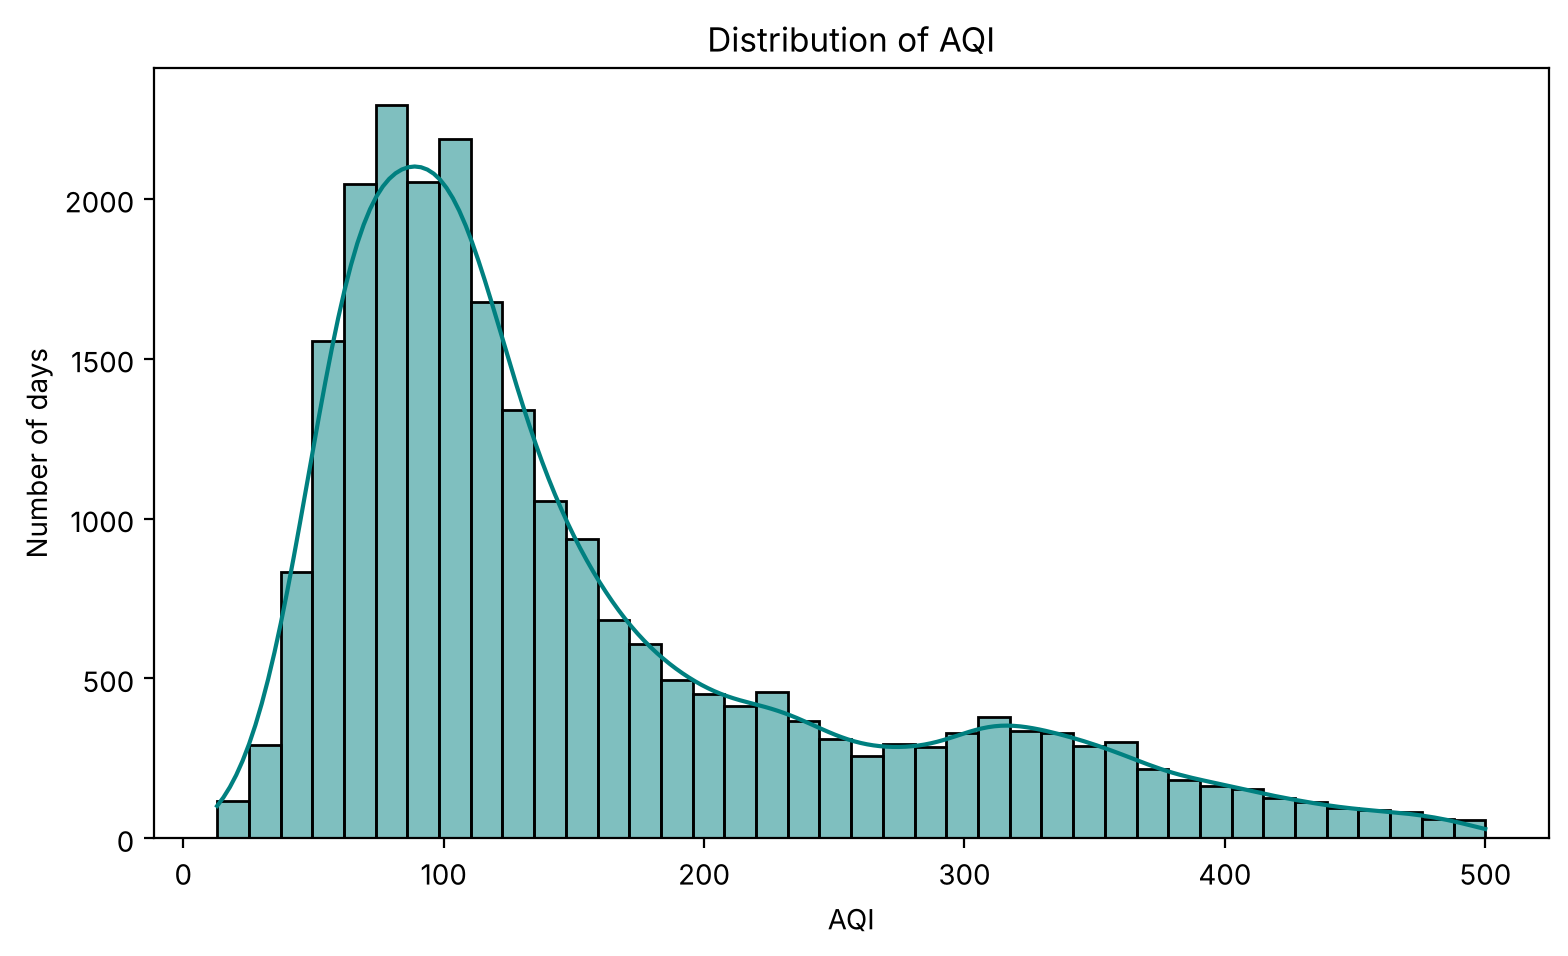

In [17]:
plt.figure(figsize=(9,5))
sns.histplot(df_clean["AQI"], bins=40, kde=True, color="teal")
plt.title("Distribution of AQI"); plt.xlabel("AQI"); plt.ylabel("Number of days")
plt.savefig(f"{IMG}/visualization_01.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** Most days have an AQI between about 50 and 200, but the distribution has a long tail to the right up to 500. This matches the mean (153) being higher than the median (116). Air quality is usually moderate, but a smaller number of days are severely polluted.

## 4.2 Bar chart: top 10 cities by average AQI

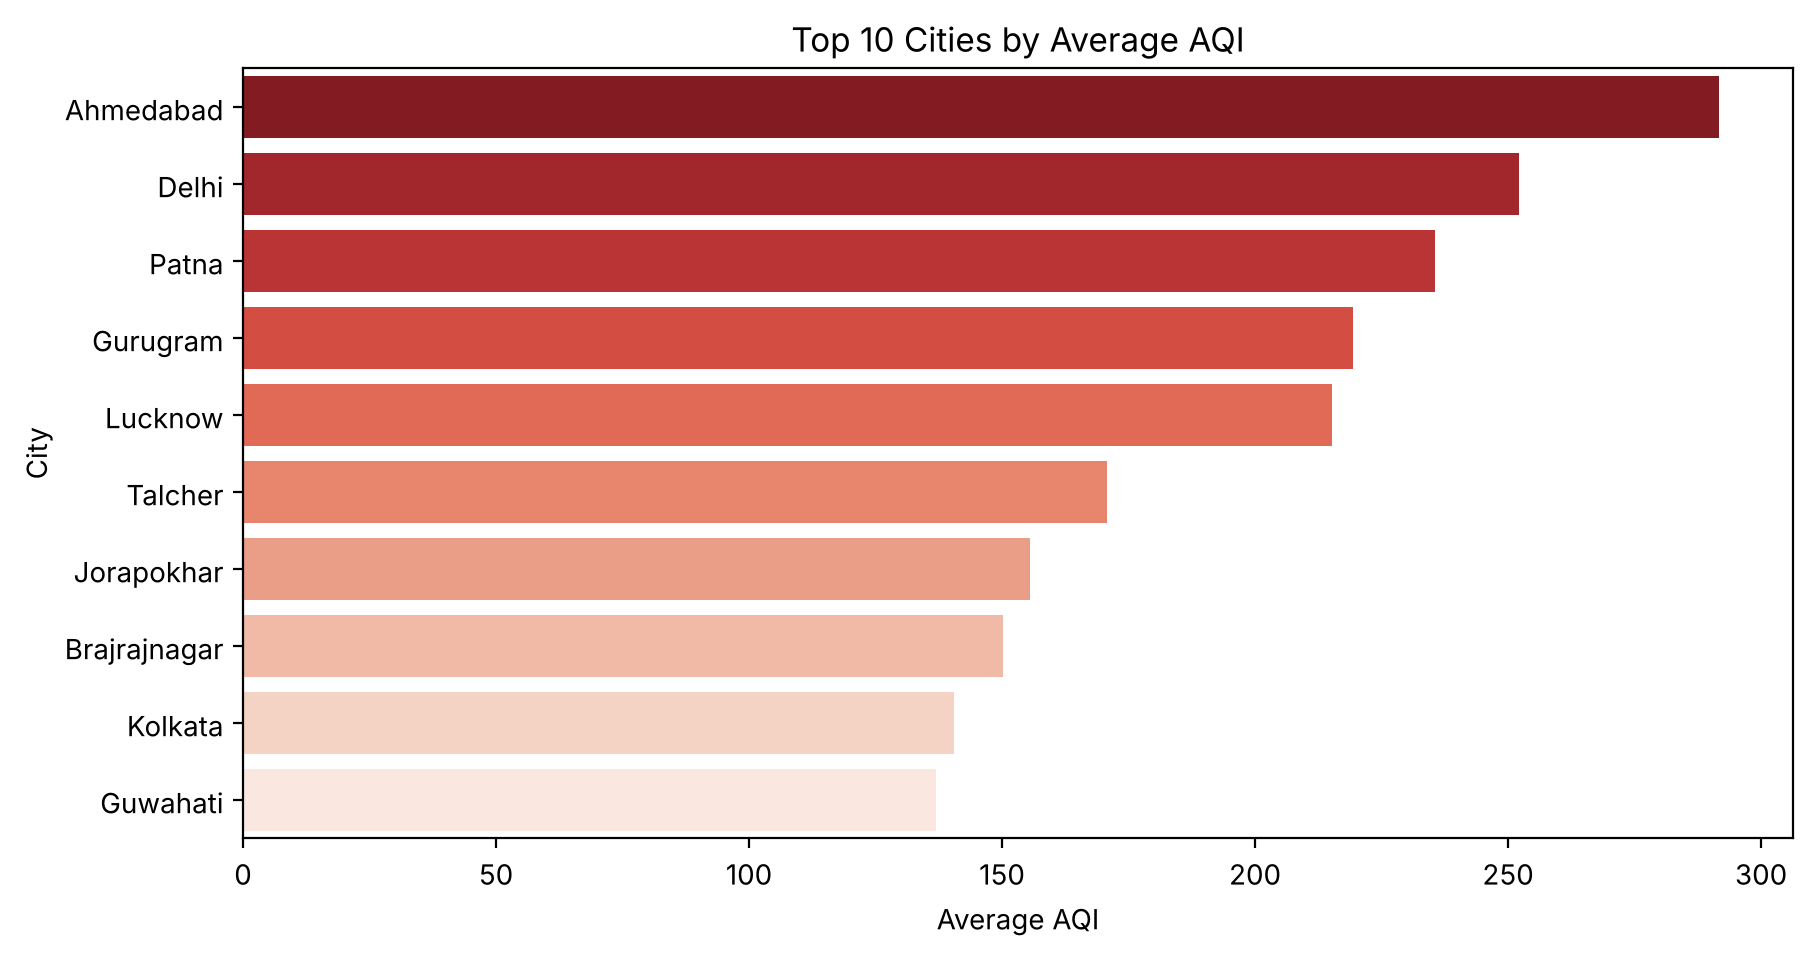

In [18]:
top = df_clean.groupby("City")["AQI"].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
sns.barplot(x=top.values, y=top.index, palette="Reds_r")
plt.title("Top 10 Cities by Average AQI"); plt.xlabel("Average AQI"); plt.ylabel("City")
plt.savefig(f"{IMG}/visualization_02.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** Ahmedabad (291.7), Delhi (252.1) and Patna (235.6) have the highest average AQI. All five top cities average above 200, which is in the Poor to Very Poor range. Ahmedabad's value should be read with care because many of its rows were removed as invalid.

## 4.3 Pie chart: share of days by AQI category

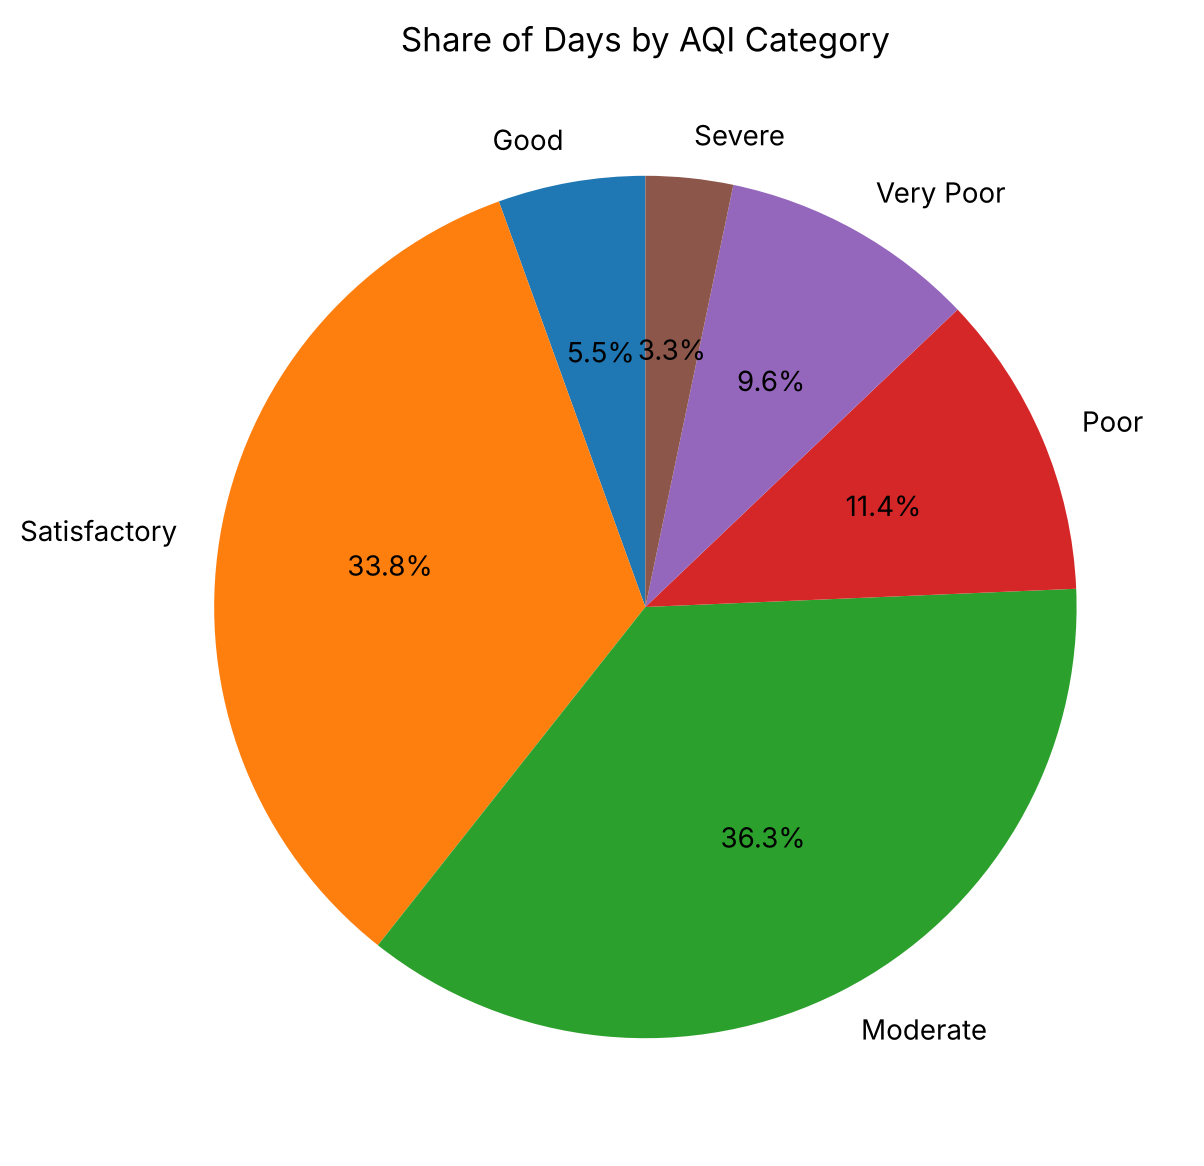

In [19]:
order = ["Good","Satisfactory","Moderate","Poor","Very Poor","Severe"]
counts = df_clean["AQI_Category"].value_counts().reindex(order)
plt.figure(figsize=(7,7))
plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Share of Days by AQI Category")
plt.savefig(f"{IMG}/visualization_03.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** Moderate (36.3%) and Satisfactory (33.8%) make up about 70% of all days. Only 5.5% of days are Good, while Poor, Very Poor and Severe together make up 24.3%, so roughly one day in four is unhealthy.

## 4.4 Count plot: number of days per AQI category

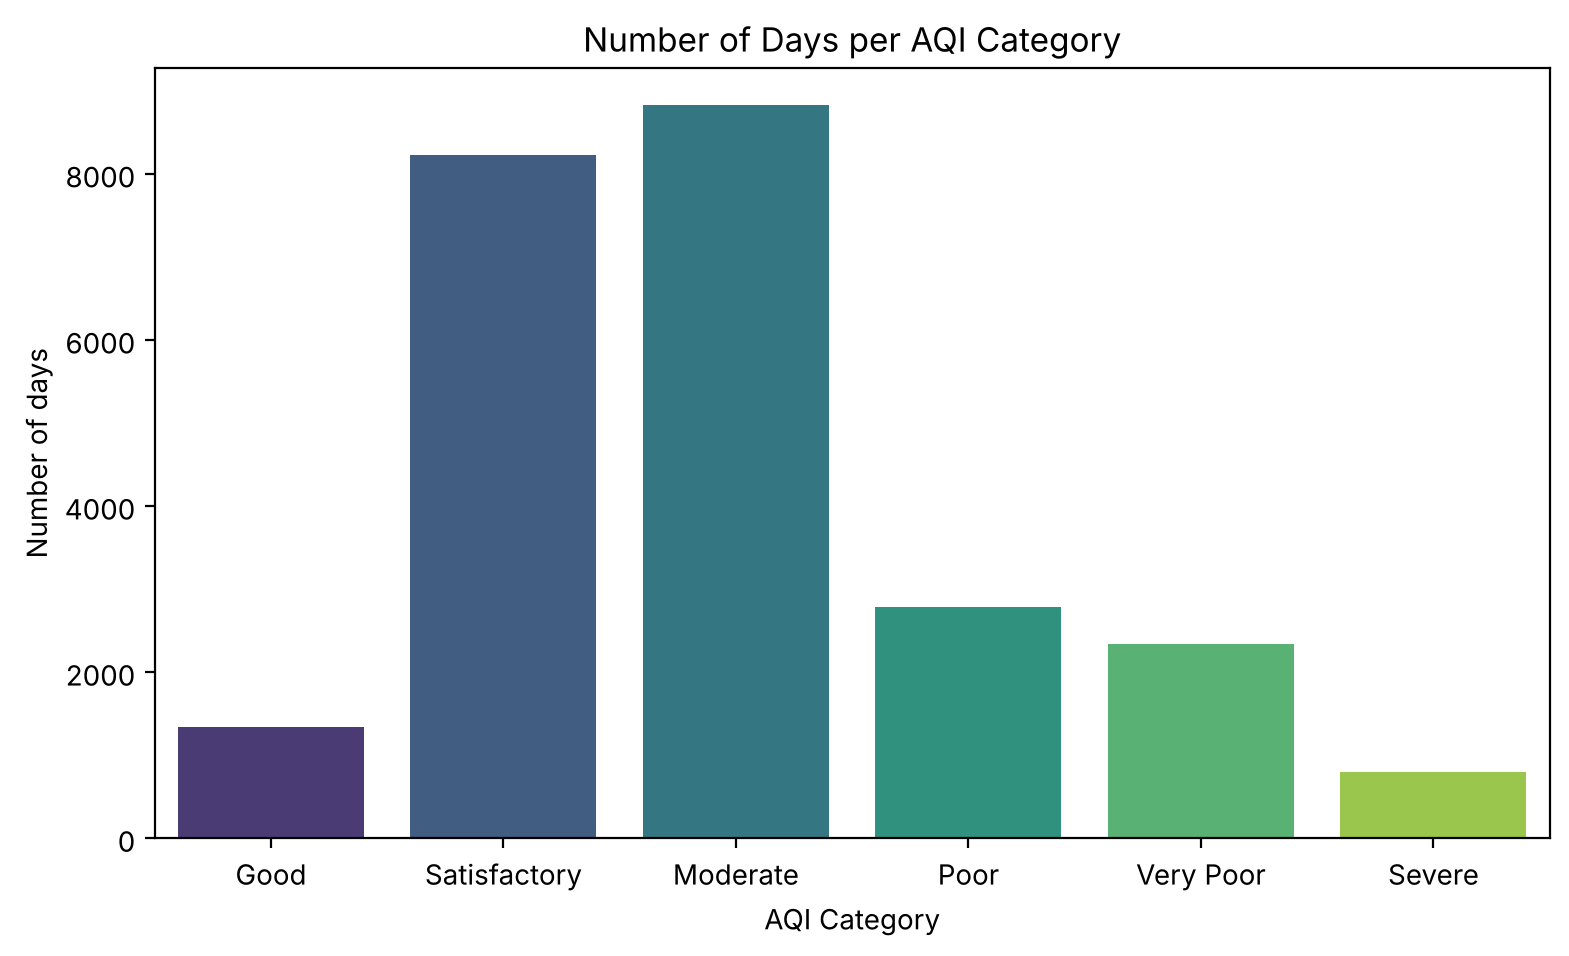

In [20]:
plt.figure(figsize=(9,5))
sns.countplot(data=df_clean, x="AQI_Category", order=order, palette="viridis")
plt.title("Number of Days per AQI Category"); plt.xlabel("AQI Category"); plt.ylabel("Number of days")
plt.savefig(f"{IMG}/visualization_04.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** Moderate is the most common category (8,829 days) and Severe is among the least common (795 days). Very few days are Good (1,341), which shows that clean air is rare in the cities covered.

## 4.5 Line chart: monthly average AQI over time

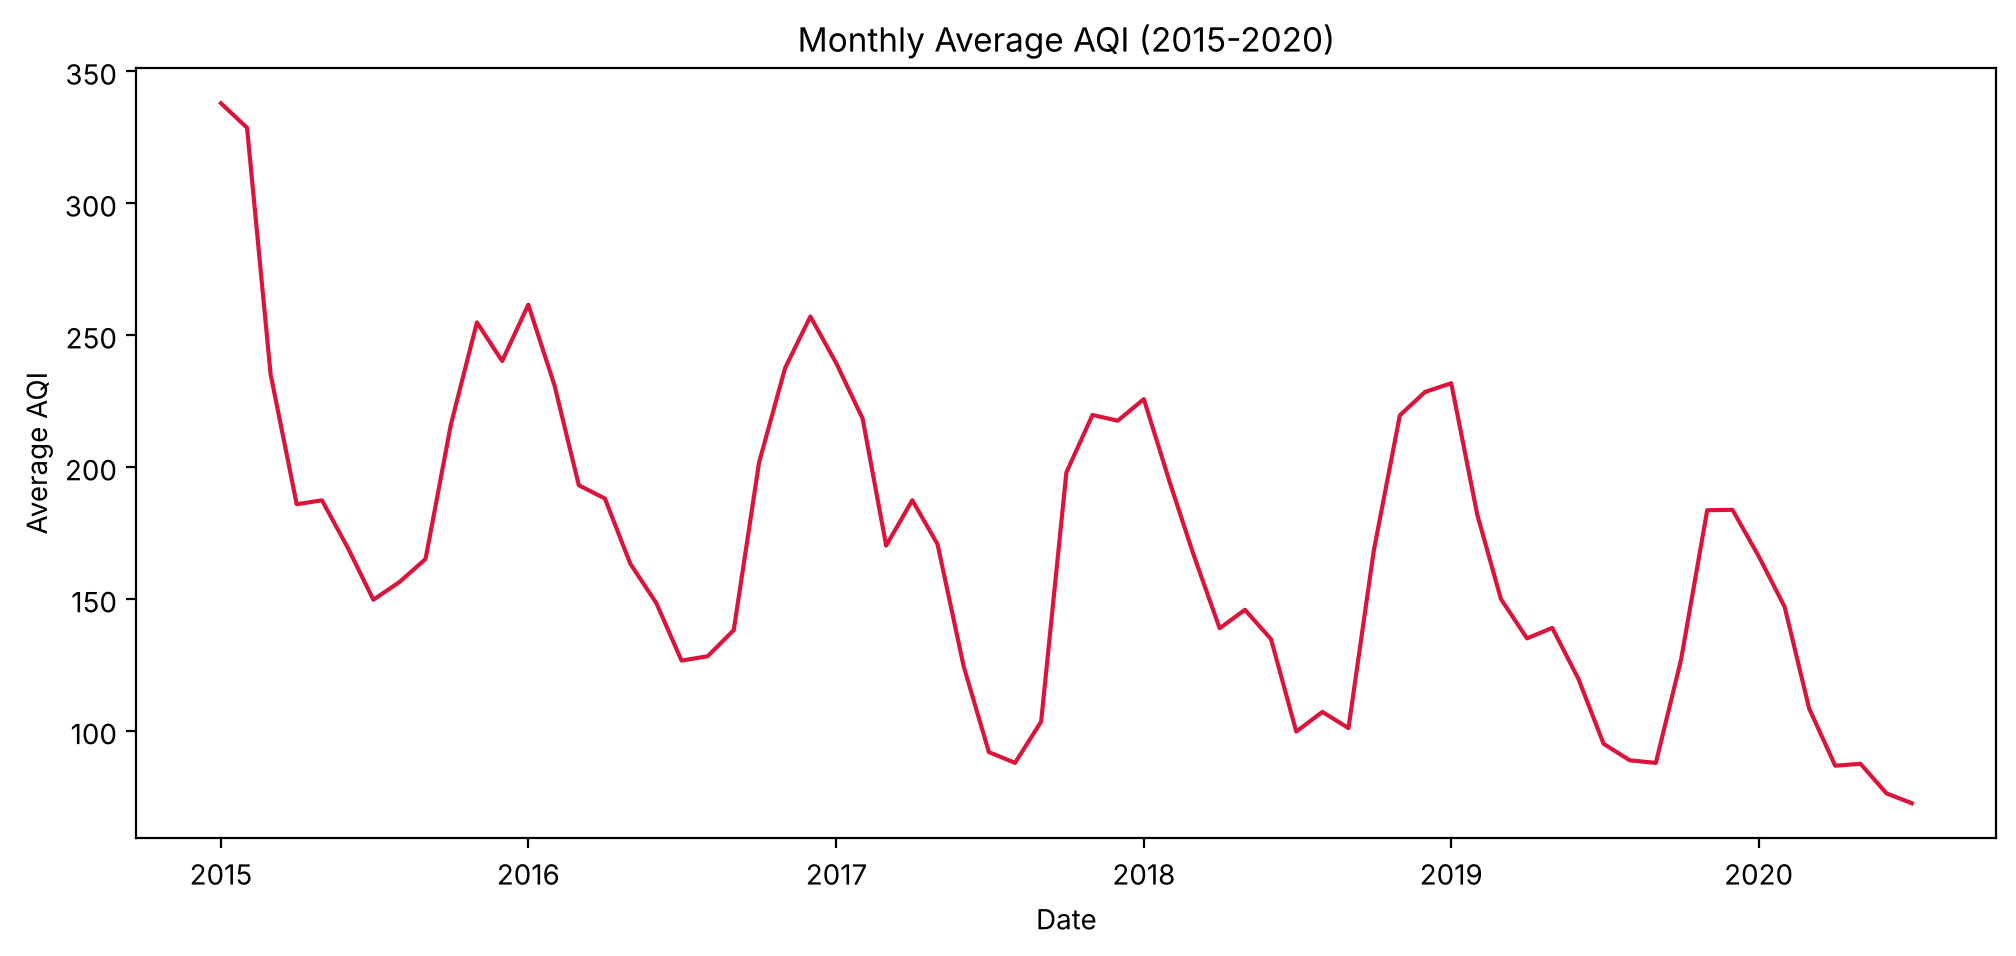

In [21]:
monthly = df_clean.groupby(df_clean["Date"].dt.to_period("M"))["AQI"].mean()
plt.figure(figsize=(12,5))
plt.plot(monthly.index.to_timestamp(), monthly.values, color="crimson")
plt.title("Monthly Average AQI (2015-2020)"); plt.xlabel("Date"); plt.ylabel("Average AQI")
plt.savefig(f"{IMG}/visualization_05.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** The line shows a clear yearly cycle: AQI rises every winter (November to January) and falls in the monsoon months (July to September). There is also a downward drift over the years. Early 2015 is very high, but only 7 cities have data in 2015, so the early values mostly reflect those cities.

## 4.6 Scatter plot: PM2.5 vs AQI

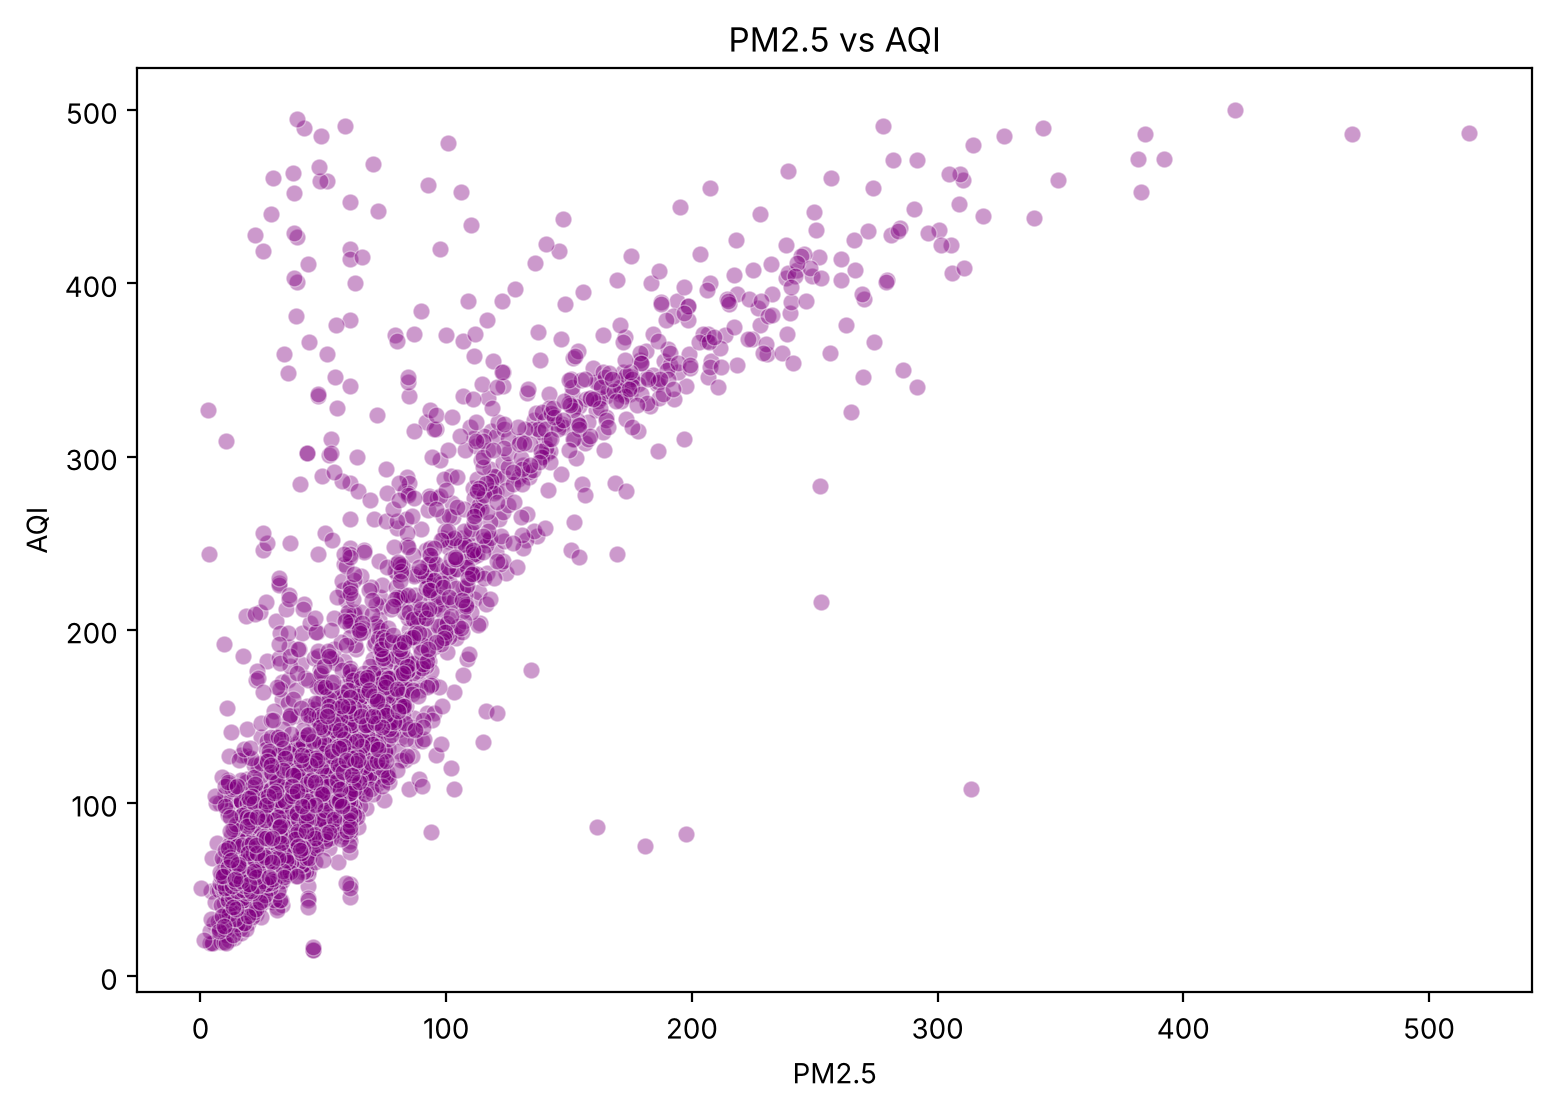

In [22]:
plt.figure(figsize=(9,6))
sns.scatterplot(data=df_clean.sample(3000, random_state=42), x="PM2_5", y="AQI", alpha=0.4, color="purple")
plt.title("PM2.5 vs AQI"); plt.xlabel("PM2.5"); plt.ylabel("AQI")
plt.savefig(f"{IMG}/visualization_06.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** AQI rises as PM2.5 rises (correlation 0.83). The points spread out at higher AQI values, meaning that other pollutants also push AQI up on some days. PM2.5 is the single most important pollutant to watch in this dataset.

## 4.7 Box plot: AQI in the 8 most polluted cities

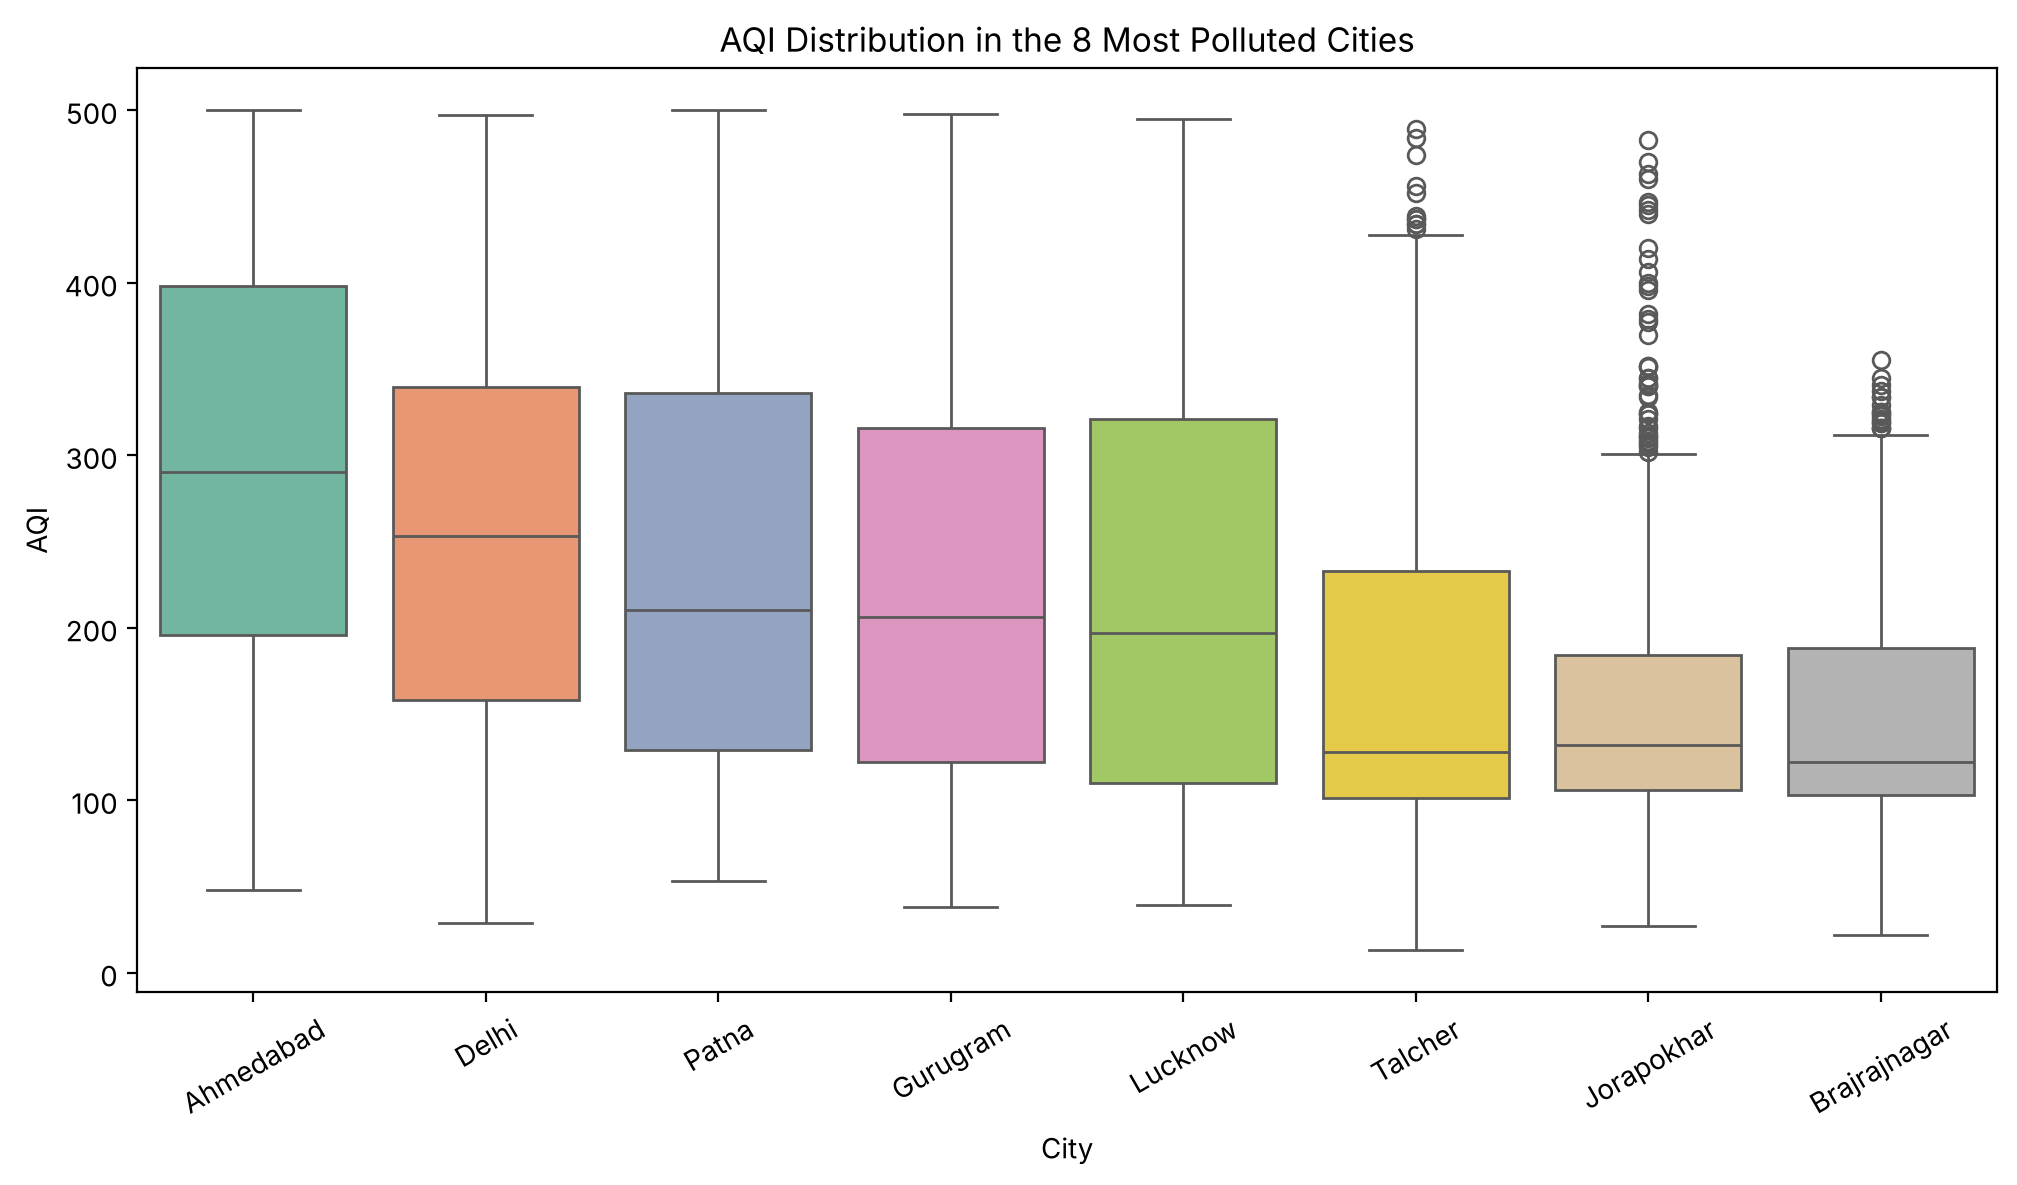

In [23]:
top8 = df_clean.groupby("City")["AQI"].mean().sort_values(ascending=False).head(8).index
plt.figure(figsize=(12,6))
sns.boxplot(data=df_clean[df_clean["City"].isin(top8)], x="City", y="AQI", order=top8, palette="Set2")
plt.title("AQI Distribution in the 8 Most Polluted Cities"); plt.xlabel("City"); plt.ylabel("AQI")
plt.xticks(rotation=30)
plt.savefig(f"{IMG}/visualization_07.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** Ahmedabad has both the highest median (about 290) and a very wide spread. Delhi, Patna, Gurugram and Lucknow have medians near 200 to 250 with wide boxes, meaning AQI changes a lot from day to day. Talcher, Jorapokhar and Brajrajnagar have lower medians but many high outliers, which means they have occasional very polluted days.

## 4.8 Correlation heatmap

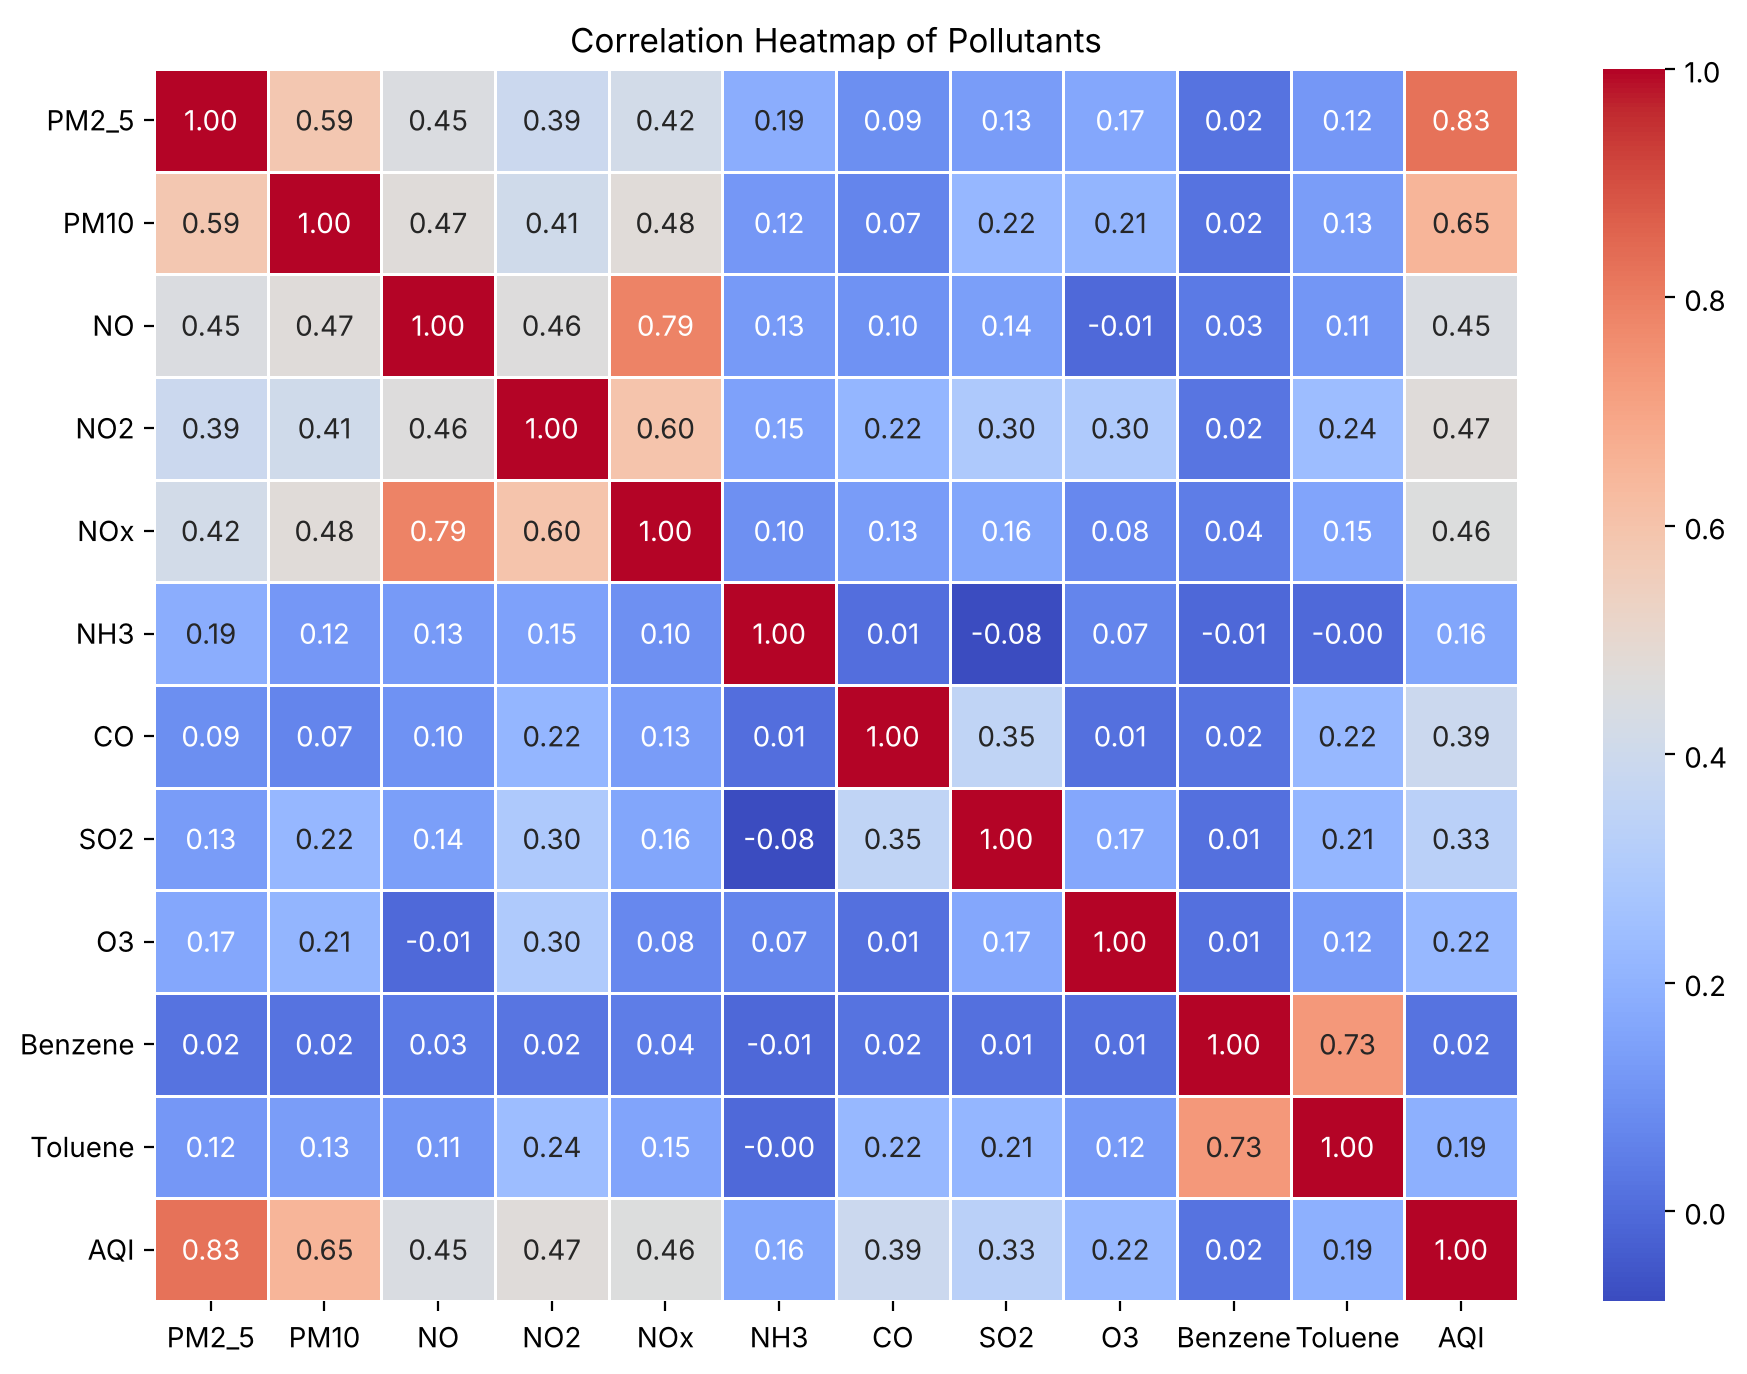

In [24]:
plt.figure(figsize=(11,8))
sns.heatmap(df_clean[pollutants].corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap of Pollutants")
plt.savefig(f"{IMG}/visualization_08.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** AQI is most strongly related to PM2.5 (0.83) and PM10 (0.65). Two pollutant pairs are also strongly related: NO and NOx (0.79) and Benzene and Toluene (0.73). Benzene (0.02) and NH3 (0.16) have almost no linear link with AQI.

## 4.9 Pair plot

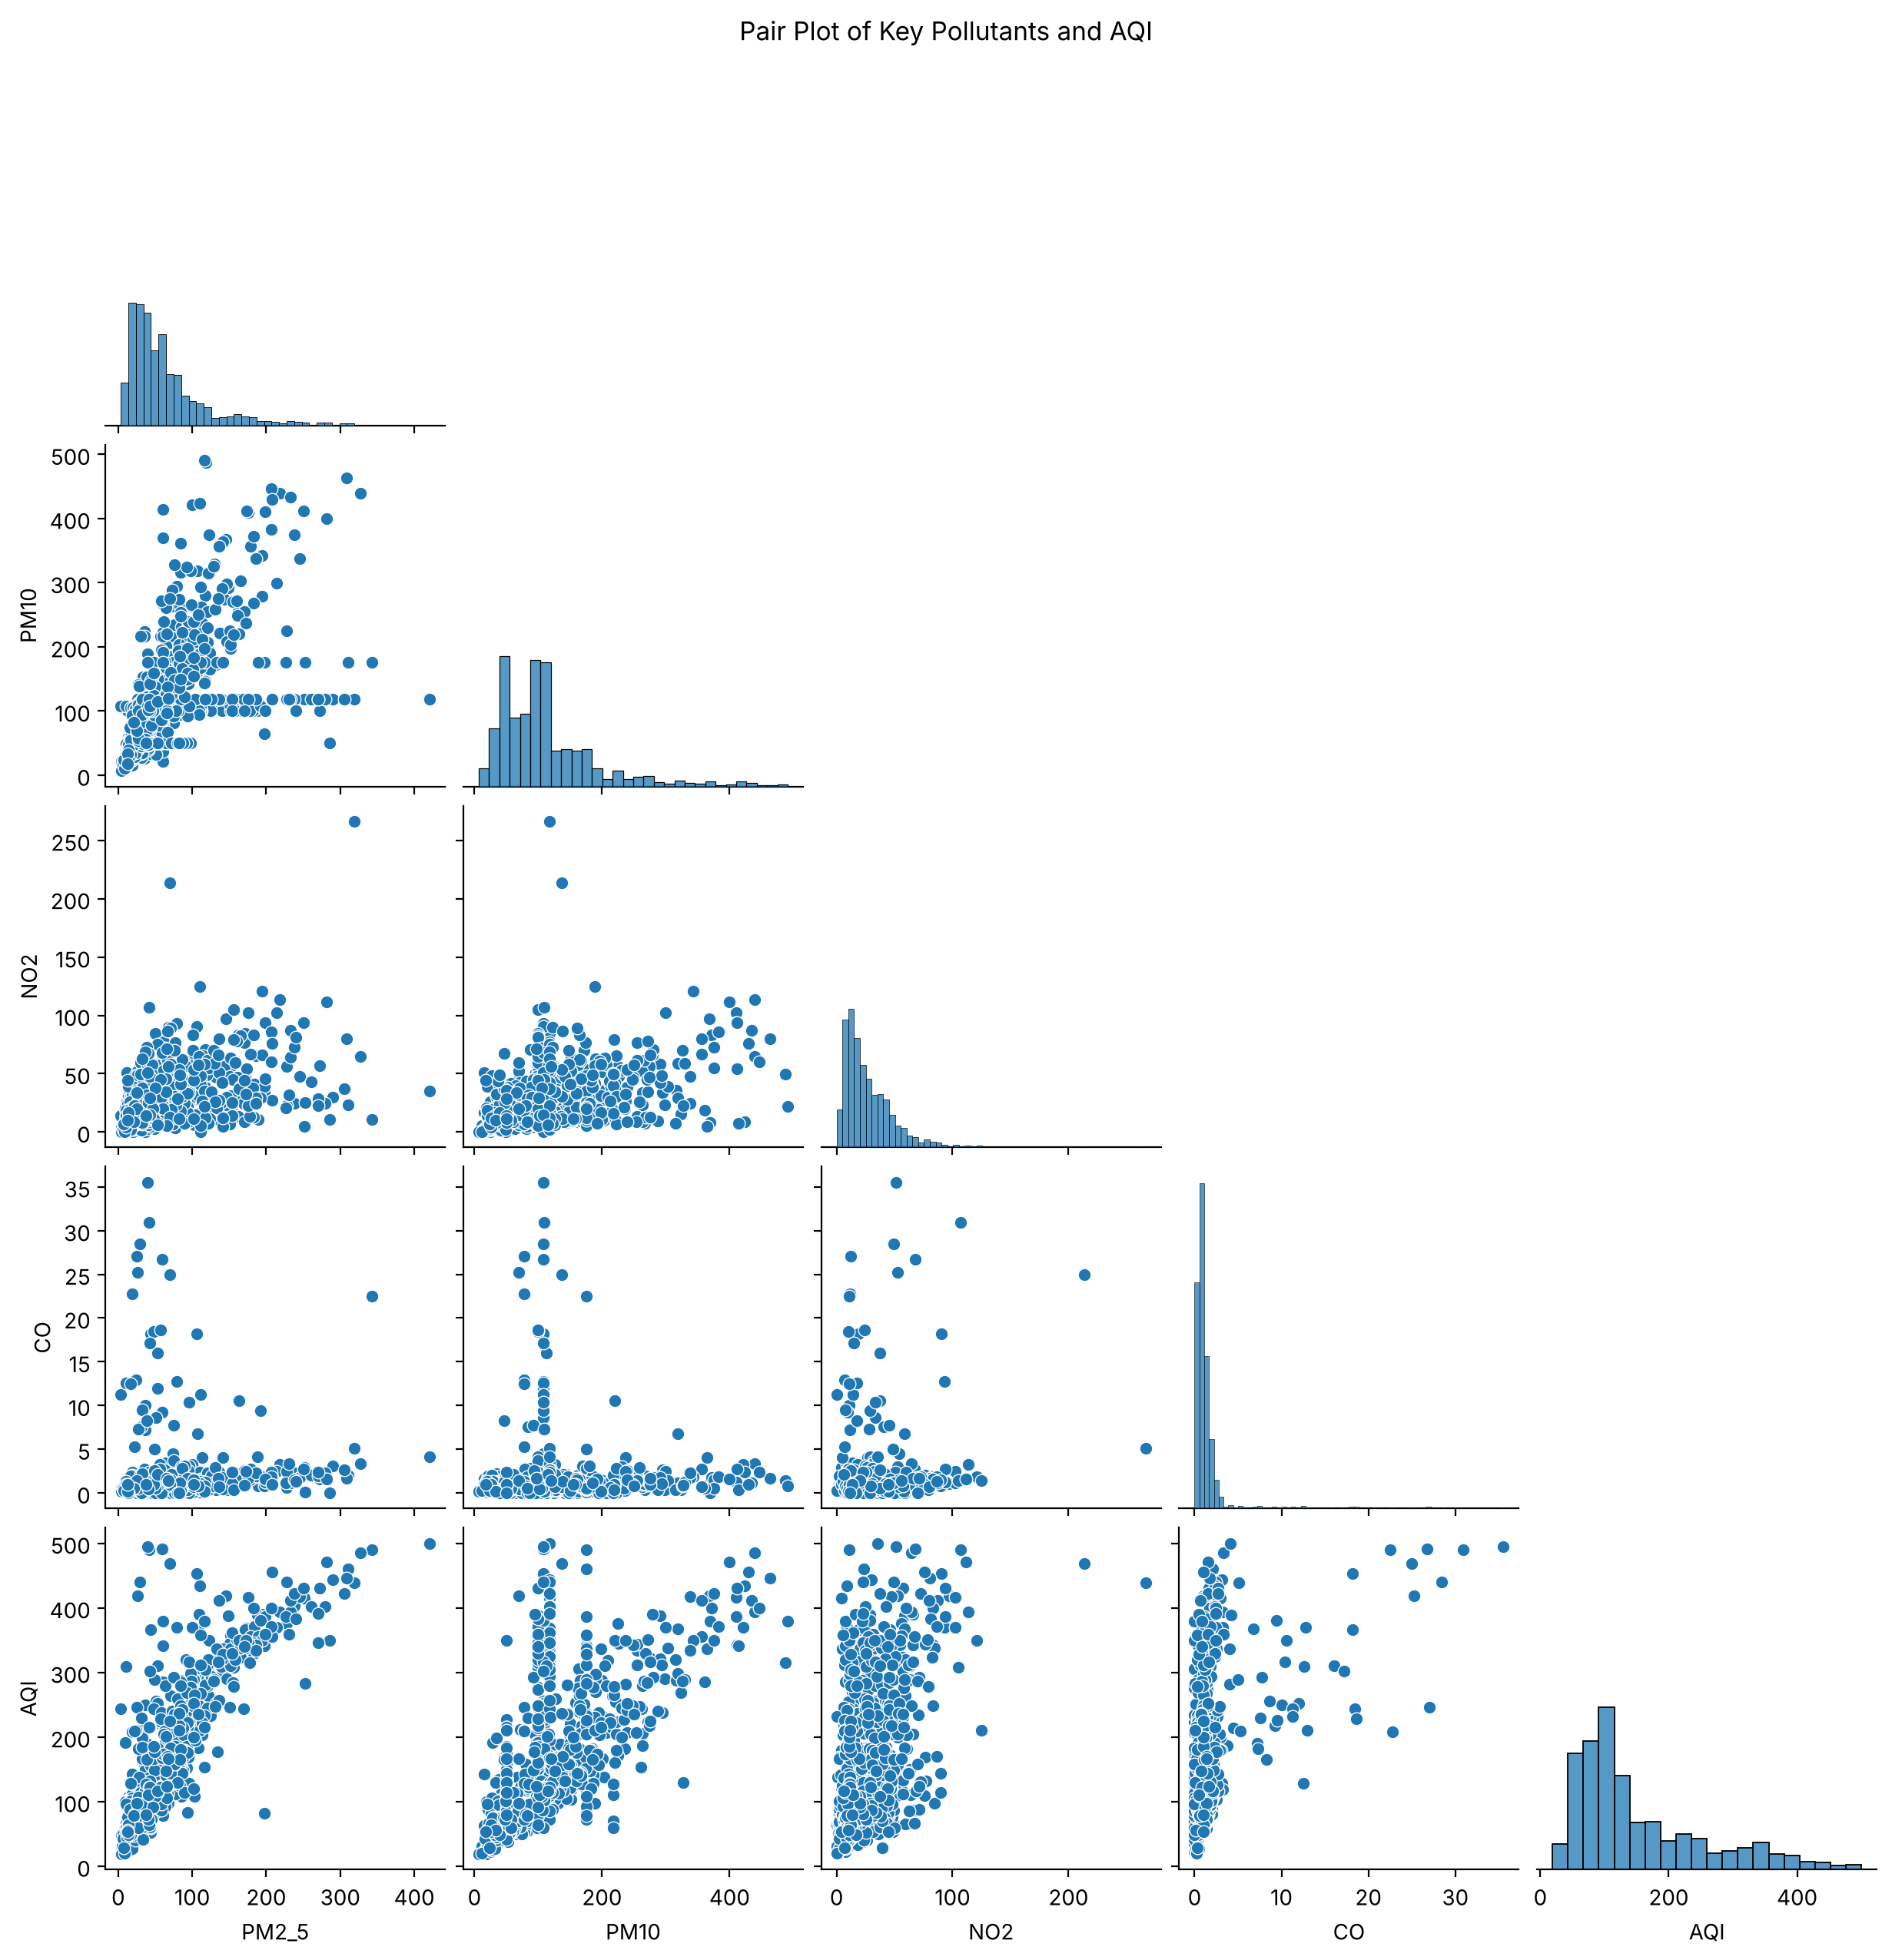

In [25]:
sample = df_clean[["PM2_5","PM10","NO2","CO","AQI"]].sample(1000, random_state=42)
g = sns.pairplot(sample, corner=True)
g.fig.suptitle("Pair Plot of Key Pollutants and AQI", y=1.02)
g.savefig(f"{IMG}/visualization_09.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** The diagonal plots show that all variables are right-skewed, with most values low and a few very high. AQI increases with PM2.5 and PM10, while CO shows a weaker pattern. This agrees with the correlation results. The horizontal band of points near PM10 = 100 to 120 comes from missing values that were filled with a city median, which is a limitation of median imputation.

## 4.10 Violin plot: AQI by year

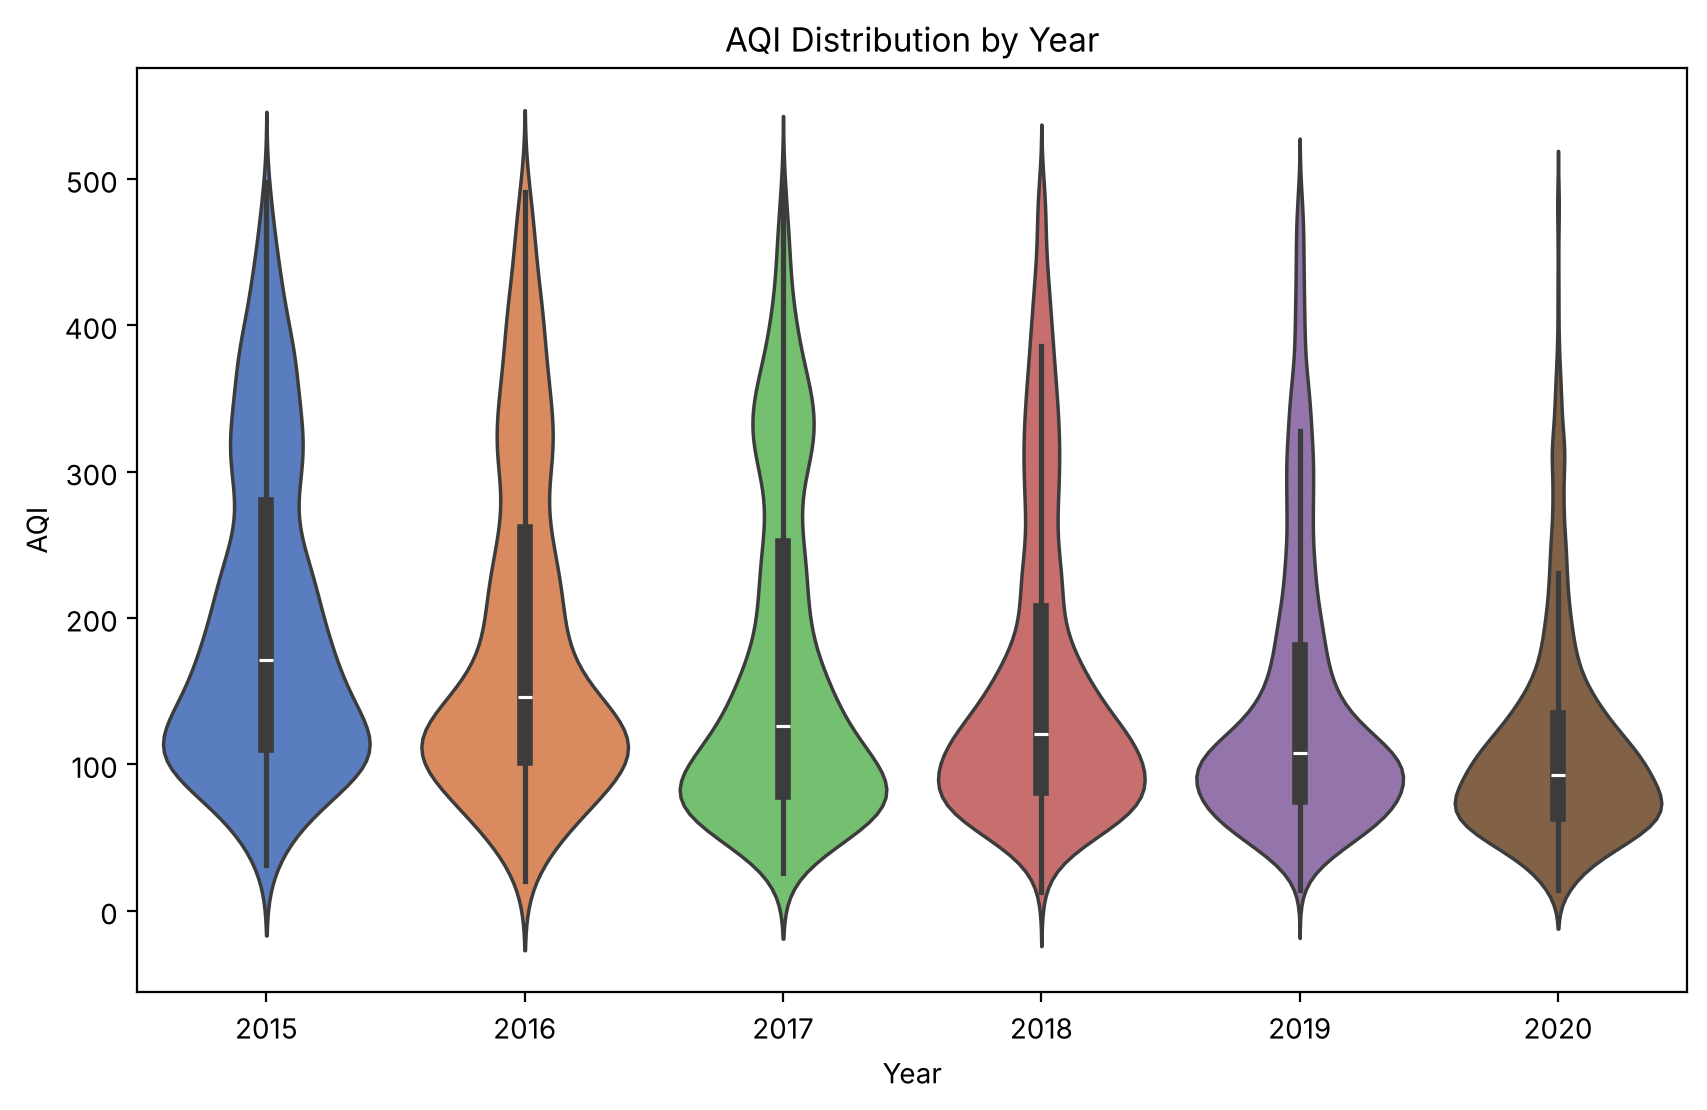

In [26]:
plt.figure(figsize=(10,6))
sns.violinplot(data=df_clean, x="Year", y="AQI", palette="muted")
plt.title("AQI Distribution by Year"); plt.xlabel("Year"); plt.ylabel("AQI")
plt.savefig(f"{IMG}/visualization_10.png", dpi=150, bbox_inches="tight"); plt.show()

**Interpretation:** The median AQI goes down from 171 in 2015 to 93 in 2020, and the distribution moves toward lower values. This should be read carefully, because the number of cities in the data grew from 7 in 2015 to 26 in 2020, and 2020 ends on 1 July.

## Extra check: same cities, same months, 2019 vs 2020
Because the set of cities changes each year, I compared only the cities that have data in January to June of both 2019 and 2020.

In [27]:
h1 = df_clean[(df_clean["Month"] <= 6) & (df_clean["Year"].isin([2019, 2020]))]
t = h1.pivot_table(index="City", columns="Year", values="AQI", aggfunc="mean").dropna()
print("Cities compared:", len(t))
print(t.mean().round(1))
print("Change: {:.1f}%".format((t[2020].mean() / t[2019].mean() - 1) * 100))

Cities compared: 20
Year
2019    159.1
2020    119.5
dtype: float64
Change: -24.9%


# Part 5: Insights and Findings

**1. Most polluted cities.** Ahmedabad has the highest average AQI (291.7), followed by Delhi (252.1) and Patna (235.6). Ahmedabad's figure is less reliable because 412 of its rows with invalid AQI (above 500) were removed.

**2. Cleanest cities.** Aizawl (34.8) and Shillong (53.8) have the lowest average AQI. Ahmedabad's average is about 8.4 times that of Aizawl. Aizawl has only 111 records, so its value rests on limited data.

**3. Seasonal pattern.** Pollution is highest in winter: December (215.1), January (213.4) and November (212.8). It is lowest in July (105.1), so winter AQI is about twice the monsoon level.

**4. Decline over the years.** Average AQI fell from 199.4 in 2015 to 110.9 in 2020 (about 44% lower). This must be read carefully: the number of cities with data grew from 7 to 26 over this period and 2020 ends on 1 July, so the comparison is not like-for-like.

**5. Fairer comparison.** For the 20 cities with data in January to June of both years, the average AQI fell from 159.1 in 2019 to 119.5 in 2020 (about 25% lower). The 2020 period includes the COVID-19 lockdown, which may explain part of the drop, but this dataset cannot prove the cause.

**6. Strongest correlations.** PM2.5 (0.83) and PM10 (0.65) are most strongly correlated with AQI. This is partly because AQI is calculated from them, but it still shows that particulate matter drives air quality in these cities.

**7. Weak correlations.** Benzene (0.02) and NH3 (0.16) have almost no linear relationship with AQI.

**8. Related pollutants.** NO and NOx (0.79) and Benzene and Toluene (0.73) move together, which suggests common sources such as traffic and fuel use.

**9. Overall air quality.** About 70% of days are Moderate (36.3%) or Satisfactory (33.8%). Poor, Very Poor and Severe days make up 24.3%, and only 5.5% of days are Good.

**10. Skewed distribution.** The mean AQI (153.35) is higher than the median (116), so the data is right-skewed. A small number of very polluted days raise the average, and the median describes a typical day better.

**11. Variation and outliers.** Benzene (std/mean = 4.94), Toluene (2.38) and CO (2.21) vary the most. Extreme values such as PM2.5 up to 868.66, Benzene up to 455.03 and CO up to 175.81 (average CO is 1.64) may be real pollution spikes or sensor errors. I kept them in the data, and the box plot shows them as outliers.

# Part 6: Final Conclusion

This project analysed daily air-quality data for 26 Indian cities from 2015 to July 2020 (29,531 records, 16 columns) from Kaggle. The data was cleaned by dropping the Xylene column (61% missing), removing rows without AQI, filling the other missing pollutant values with city-wise medians, converting `Date` to datetime, renaming two columns and removing 543 rows with invalid AQI above 500. The cleaned dataset has 24,307 rows. I then calculated descriptive statistics and correlations and created ten visualizations: histogram, bar chart, pie chart, count plot, line chart, scatter plot, box plot, heatmap, pair plot and violin plot.

The main findings are that Ahmedabad, Delhi and Patna are the most polluted cities, pollution is about twice as high in winter as in the monsoon, and PM2.5 and PM10 are the pollutants most closely linked with AQI. About one day in four falls in the Poor, Very Poor or Severe categories. Average AQI is lower in later years, but the changing number of cities makes this trend hard to interpret, and the like-for-like check for 2019 and 2020 shows a smaller fall of about 25%. Through this project I learned how to inspect and clean a real dataset, how to justify cleaning choices, and how to read statistics and charts carefully. The results could help identify high-risk cities and seasons for air-quality planning, and the cleaned data can be used for dashboards and prediction models in later tasks.